Step 1: Import the required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

Step 2: Generate the synthetic two-class dataset

In [2]:
X, y = make_moons(
    n_samples=1000,
    noise=0.25,
    random_state=42
)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Classes:", np.unique(y))

Feature shape: (1000, 2)
Target shape: (1000,)
Classes: [0 1]


In [20]:


nn_model = Sequential([
    Input(shape=(2,)),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

nn_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)
history = nn_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    verbose=1
)

nn_model.summary()

Epoch 1/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7614 - loss: 0.5914 - val_accuracy: 0.7467 - val_loss: 0.5708
Epoch 2/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7843 - loss: 0.5515 - val_accuracy: 0.7667 - val_loss: 0.5295
Epoch 3/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8071 - loss: 0.5183 - val_accuracy: 0.7867 - val_loss: 0.4947
Epoch 4/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8100 - loss: 0.4902 - val_accuracy: 0.8000 - val_loss: 0.4659
Epoch 5/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8171 - loss: 0.4665 - val_accuracy: 0.8067 - val_loss: 0.4412
Epoch 6/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8214 - loss: 0.4467 - val_accuracy: 0.8267 - val_loss: 0.4196
Epoch 7/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8271 - loss: 0.4291 - val_accuracy: 0.8400 - val_loss: 0.4017
Epoch 8/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8371 - loss: 0.4146 - val_accuracy: 0.8467 - 

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 16)             │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 197 (792.00 B)

 Trainable params: 65 (260.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 132 (532.00 B)

Step 3: Visualize the dataset

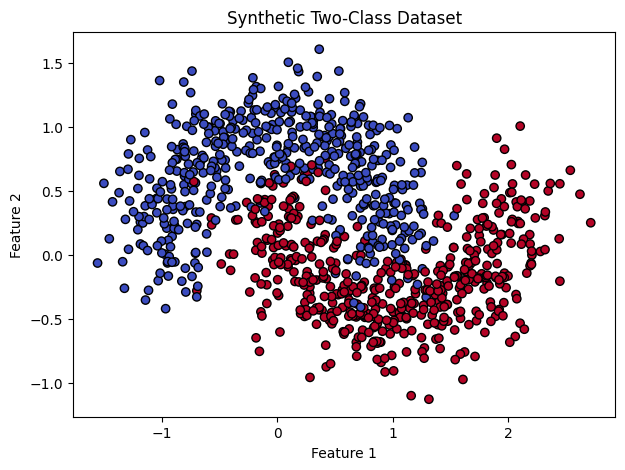

In [21]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="coolwarm",
    edgecolors="black"
)

plt.title("Synthetic Two-Class Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

Step 4: Split the dataset

In [22]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 700
Validation samples: 150
Testing samples: 150


Step 5: Scale the features

In [23]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


Step 6: Build and train the linear model

In [24]:
linear_model = LogisticRegression(random_state=42)

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

print("Linear Model Accuracy:",
      accuracy_score(y_test, linear_pred))

print("\nClassification Report:")
print(classification_report(y_test, linear_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, linear_pred))

Linear Model Accuracy: 0.8866666666666667

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.93      0.89        75
           1       0.93      0.84      0.88        75

    accuracy                           0.89       150
   macro avg       0.89      0.89      0.89       150
weighted avg       0.89      0.89      0.89       150

Confusion Matrix:
[[70  5]
 [12 63]]


Step 7: Create a neural network model

In [25]:
def build_model(hidden_units=16, learning_rate=0.001):

    model = Sequential([
        Input(shape=(2,)),
        Dense(hidden_units, activation="relu"),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

Step 8: Train the neural network

tf.keras.utils.set_random_seed(42)

nn_model = build_model(
    hidden_units=16,
    learning_rate=0.001
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = nn_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Step 9: Evaluate the neural network

In [26]:
nn_prob = nn_model.predict(X_test, verbose=0).ravel()

nn_pred = (nn_prob >= 0.5).astype(int)

print("Neural Network Results")
print("Accuracy:", accuracy_score(y_test, nn_pred))
print("Precision:", precision_score(y_test, nn_pred, zero_division=0))
print("Recall:", recall_score(y_test, nn_pred, zero_division=0))
print("F1-score:", f1_score(y_test, nn_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, nn_pred))

Neural Network Results
Accuracy: 0.9466666666666667
Precision: 0.971830985915493
Recall: 0.92
F1-score: 0.9452054794520548

Confusion Matrix:
[[73  2]
 [ 6 69]]


Step 10: Plot the training and validation loss

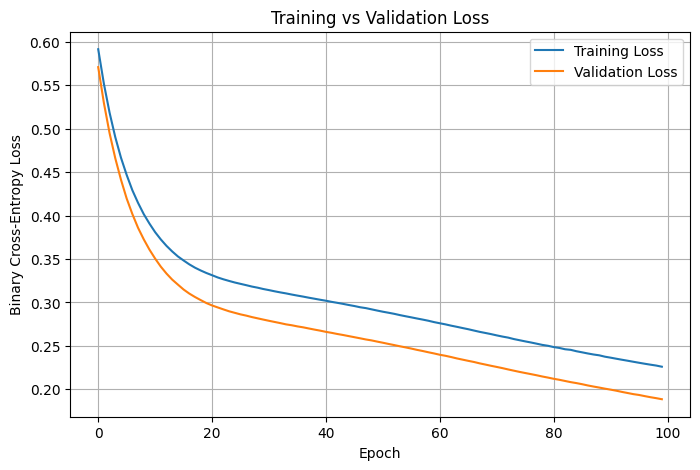

In [27]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(True)
plt.show()

Step 11: Experiment with hidden-layer size and learning rate

In [28]:
results = []

for units in [8, 16, 32]:
    for lr in [0.01, 0.001]:

        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(42)

        model = build_model(
            hidden_units=units,
            learning_rate=lr
        )

        model.fit(
            X_train,
            y_train,
            validation_data=(X_val, y_val),
            epochs=100,
            batch_size=32,
            callbacks=[
                EarlyStopping(
                    monitor="val_loss",
                    patience=10,
                    restore_best_weights=True
                )
            ],
            verbose=0
        )

        predictions = (
            model.predict(X_val, verbose=0).ravel() >= 0.5
        ).astype(int)

        results.append({
            "Model": "Neural Network",
            "Hidden Units": units,
            "Learning Rate": lr,
            "Validation Accuracy": accuracy_score(y_val, predictions),
            "Validation F1-score": f1_score(
                y_val, predictions, zero_division=0
            )
        })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))


         Model  Hidden Units  Learning Rate  Validation Accuracy  Validation F1-score
Neural Network             8          0.010               0.9533               0.9530
Neural Network             8          0.001               0.9000               0.8980
Neural Network            16          0.010               0.9733               0.9733
Neural Network            16          0.001               0.9400               0.9396
Neural Network            32          0.010               0.9600               0.9600
Neural Network            32          0.001               0.9533               0.9524


Step 12: Create the comparison table

In [29]:
best_config = results_df.loc[
    results_df["Validation F1-score"].idxmax()
]

print("Best configuration:")
print(best_config)

# Train the selected neural network configuration
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

best_model = build_model(
    hidden_units=int(best_config["Hidden Units"]),
    learning_rate=float(best_config["Learning Rate"])
)

best_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True
        )
    ],
    verbose=0
)

# Evaluate both models on the test set
best_pred = (
    best_model.predict(X_test, verbose=0).ravel() >= 0.5
).astype(int)

comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, linear_pred),
        "Precision": precision_score(y_test, linear_pred, zero_division=0),
        "Recall": recall_score(y_test, linear_pred, zero_division=0),
        "F1-score": f1_score(y_test, linear_pred, zero_division=0)
    },
    {
        "Model": "Best Neural Network",
        "Accuracy": accuracy_score(y_test, best_pred),
        "Precision": precision_score(y_test, best_pred, zero_division=0),
        "Recall": recall_score(y_test, best_pred, zero_division=0),
        "F1-score": f1_score(y_test, best_pred, zero_division=0)
    }
])

print("\nFinal Model Comparison")
print(comparison.round(4).to_string(index=False))

Best configuration:
Model                  Neural Network
Hidden Units                       16
Learning Rate                    0.01
Validation Accuracy          0.973333
Validation F1-score          0.973333
Name: 2, dtype: object

Final Model Comparison
              Model  Accuracy  Precision  Recall  F1-score
Logistic Regression    0.8867     0.9265  0.8400    0.8811
Best Neural Network    0.9600     0.9859  0.9333    0.9589


Step 13: Display the final result

In [30]:
winner = comparison.loc[comparison["F1-score"].idxmax()]

print("Best model based on test F1-score:", winner["Model"])
print("Accuracy:", round(winner["Accuracy"], 4))
print("F1-score:", round(winner["F1-score"], 4))

Best model based on test F1-score: Best Neural Network
Accuracy: 0.96
F1-score: 0.9589
